# Mission 02: Streaming Revenue into Delta Lake

The operations dashboard shows taxi revenue per borough in 15-minute windows. Today a batch job recomputes everything
every hour. Replace it with a **Structured Streaming** job that reads new trip files as they arrive and keeps a
**Delta table** up to date with `MERGE`, survives restarts without double counting, and handles late files.

**Lessons used:** 04 (joins), 08 (Structured Streaming and watermarks), 09 (Delta Lake with Spark).

**Data:** NYC yellow taxi trips, 2024-02-01 to 2024-02-03, delivered as hourly Parquet files; the zone lookup table.

**Services:** none (Spark and Delta run locally in the notebook).

In [1]:
import shutil
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from delta import configure_spark_with_delta_pip
from delta.tables import DeltaTable
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets                                   # course helper: pinned datasets

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "mission02"
shutil.rmtree(WORK, ignore_errors=True)
INBOX, GOLD, CHECKPOINT = WORK / "inbox", WORK / "gold_revenue", WORK / "checkpoint"
INBOX.mkdir(parents=True)

builder = (SparkSession.builder.master("local[4]").appName("m13-mission02")
           .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "4")
           .config("spark.ui.showConsoleProgress", "false").config("spark.sql.session.timeZone", "UTC")
           .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
           .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog"))
spark = configure_spark_with_delta_pip(builder).getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

# The source system: 72 hourly files. Files arrive in three waves; wave 3 also re-delivers two files of hours that
# were missing earlier (late files).
trips = pd.read_parquet(datasets.taxi("2024-02"), columns=["tpep_pickup_datetime", "PULocationID", "total_amount"])
trips = trips[(trips.tpep_pickup_datetime >= "2024-02-01") & (trips.tpep_pickup_datetime < "2024-02-04")]
trips = trips.rename(columns={"tpep_pickup_datetime": "pickup_at", "PULocationID": "pu_zone", "total_amount": "total"})
hours = sorted(trips.pickup_at.dt.floor("h").unique())
late_hours = {hours[10], hours[30]}                 # these two hours are delivered late, in wave 3
waves = {1: [h for h in hours[:24] if h not in late_hours], 2: [h for h in hours[24:48] if h not in late_hours],
         3: hours[48:] + sorted(late_hours)}

def deliver(wave: int) -> int:
    for h in waves[wave]:
        part = trips[trips.pickup_at.dt.floor("h") == h]
        part.to_parquet(INBOX / f"trips_{pd.Timestamp(h):%Y%m%d_%H}.parquet", index=False)
    return len(waves[wave])

print(f"{len(trips):,} trips in {len(hours)} hourly files | late hours: {sorted(str(pd.Timestamp(h)) for h in late_hours)}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 22:58:11 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/17 22:58:11 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/mnt/d/MuhammetAliVarlik/PythonProjects/FromZeroToHero-DataScience-AI-Cloud/FromZeroToHero-DataScience-AI-Cloud/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-1fbcf8dc-c597-494f-901d-b9b88b20eb24;1.0
	confs: [default]


	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central


	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central


	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central


... (5 outputs left out)

	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 8048ms :: artifacts dl 17ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]
	com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 from central in [default]
	com.github.luben#zstd-jni;1.5.7-3 from central in [default]
	com.google.code.findbugs#jsr305;3.0.2 from central in [default]
	commons-logging#commons-logging;1.3.0 from central in [default]
	commons-pool#commons-pool;1.6 from central in [default]
	io.airlift#aircompressor;2.0.2 from central in [default]
	io.delta#delta-kernel-api;4.4.1 from central in [default]


26/11/17 22:58:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


326,067 trips in 72 hourly files | late hours: ['2024-02-01 10:00:00', '2024-02-02 06:00:00']


## Tasks

1. **Stream.** Read `INBOX` as a streaming file source (give the schema explicitly; at most 8 files per trigger).
   Join the static zone table to get the borough.
2. **Window.** Count trips and sum revenue per borough in 15-minute event-time windows, with a watermark.
3. **Upsert.** In `foreachBatch`, `MERGE` each micro-batch into the Delta table `GOLD` on (window start, borough),
   so a window that receives more trips later is updated, not duplicated. Use `trigger(availableNow=True)`.
4. **Restart.** Deliver wave 1, run the stream, stop. Deliver wave 2, run again with the same checkpoint. Deliver
   wave 3 (with two late files), run again. Show which files each run processed and that nothing was counted twice.
5. **Check.** Compare `GOLD` with a batch computation over all files. Explain every difference (the watermark).
   Run once more with a watermark long enough to accept the late files and show that the difference disappears.
6. **History.** Use the Delta history and time travel to show the table after each run.
7. **Explain.** Five sentences for the dashboard team: what is exactly-once here, what the watermark costs, and what
   to monitor in production.

## Solution

### 1–3. The streaming job

The window aggregation runs in `update` mode: each micro-batch emits only the windows that changed. `foreachBatch`
turns these rows into a `MERGE`, which makes the sink idempotent: replaying a batch writes the same values again.

In [2]:
schema = "pickup_at TIMESTAMP_NTZ, pu_zone BIGINT, total DOUBLE"
zones = (spark.read.csv(str(datasets.fetch("taxi_zone_lookup.csv")), header=True, inferSchema=True)
         .select(F.col("LocationID").cast("bigint").alias("pu_zone"), "Borough"))

def upsert(batch_df, batch_id: int) -> None:
    rows = batch_df.select(F.col("window.start").alias("window_start"), "Borough", "trips", "revenue")
    if not DeltaTable.isDeltaTable(spark, str(GOLD)):
        rows.write.format("delta").save(str(GOLD))
        return
    (DeltaTable.forPath(spark, str(GOLD)).alias("t")
     .merge(rows.alias("s"), "t.window_start = s.window_start AND t.Borough = s.Borough")
     .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())

def run_stream(watermark: str, checkpoint: Path) -> list[dict]:
    stream = (spark.readStream.schema(schema).option("maxFilesPerTrigger", 8).parquet(str(INBOX))
              .join(zones, "pu_zone")
              .withColumn("pickup_at", F.col("pickup_at").cast("timestamp"))   # watermarks need TIMESTAMP, not TIMESTAMP_NTZ
              .withWatermark("pickup_at", watermark)
              .groupBy(F.window("pickup_at", "15 minutes"), "Borough")
              .agg(F.count("*").alias("trips"), F.round(F.sum("total"), 2).alias("revenue")))
    q = (stream.writeStream.outputMode("update").foreachBatch(upsert)
         .option("checkpointLocation", str(checkpoint)).trigger(availableNow=True).start())
    q.awaitTermination()
    return [{"batch": p["batchId"], "input rows": p["numInputRows"]} for p in q.recentProgress if p["numInputRows"]]

### 4. Three deliveries, three runs, one checkpoint

In [3]:
runs = []
for wave in [1, 2, 3]:
    files = deliver(wave)
    progress = run_stream("30 minutes", CHECKPOINT)
    version = DeltaTable.forPath(spark, str(GOLD)).history(1).collect()[0]["version"]
    runs.append({"run": wave, "files delivered": files, "micro-batches": len(progress),
                 "rows read": sum(p["input rows"] for p in progress), "delta version": version})
runs = pd.DataFrame(runs)
print(runs.to_string(index=False))
print("rows read in total:", int(runs["rows read"].sum()), "| trips in all files:", len(trips))

 run  files delivered  micro-batches  rows read  delta version
   1               23              3     104756              2
   2               23              3     104046              5
   3               26              4     117265              8
rows read in total: 326067 | trips in all files: 326067


*Insight: Each run read only the files that arrived since the previous run: the checkpoint stores which files are
done, and the sum of rows read equals the number of trips delivered. Exactly-once here means "each file is
processed once, and the MERGE makes a repeated batch harmless".*

### 5. Compare with a batch computation

In [4]:
truth = (spark.read.parquet(str(INBOX)).join(zones, "pu_zone")
         .withColumn("pickup_at", F.col("pickup_at").cast("timestamp"))
         .groupBy(F.window("pickup_at", "15 minutes").start.alias("window_start"), "Borough")
         .agg(F.count("*").alias("trips_batch")))

def compare(path: Path) -> pd.DataFrame:
    gold = spark.read.format("delta").load(str(path))
    c = truth.join(gold, ["window_start", "Borough"], "left").fillna({"trips": 0}).toPandas()
    return c[c.trips_batch != c.trips]

diff = compare(GOLD)
print(f"windows that differ: {len(diff)} | trips missing in the stream: {int((diff.trips_batch - diff.trips).sum())}")
print("hours of the differing windows:", sorted({str(pd.Timestamp(t).floor('h')) for t in diff.window_start}))

windows that differ: 41 | trips missing in the stream: 6662
hours of the differing windows: ['2024-02-01 10:00:00', '2024-02-02 06:00:00']


The missing trips are exactly the two late files: when they arrived, the watermark (newest event time minus 30
minutes) had passed their windows long ago, so Spark dropped them. A longer watermark accepts them, at the price of
keeping more windows in state and publishing final values later.

In [5]:
shutil.rmtree(GOLD); shutil.rmtree(CHECKPOINT)
run_stream("72 hours", CHECKPOINT)                    # all files are already in the inbox: one run
diff_long = compare(GOLD)
print(f"watermark 72 hours -> windows that differ: {len(diff_long)}")

watermark 72 hours -> windows that differ: 0


### 6. History and time travel

The 72-hour run replaced the table, so the history now shows the micro-batches of that single run. Each micro-batch
is one Delta version, and any version can be read back.

 version operation  rows written
       0     WRITE           130
       1     MERGE           172
       2     MERGE           159
       3     MERGE           153
       4     MERGE           177
       5     MERGE           154
       6     MERGE           146
       7     MERGE           169
       8     MERGE           160


trips in the table per version: [(0, 9912), (1, 56935), (2, 107268), (3, 124182), (4, 171519), (5, 219344), (6, 232615), (7, 279049), (8, 326067)]


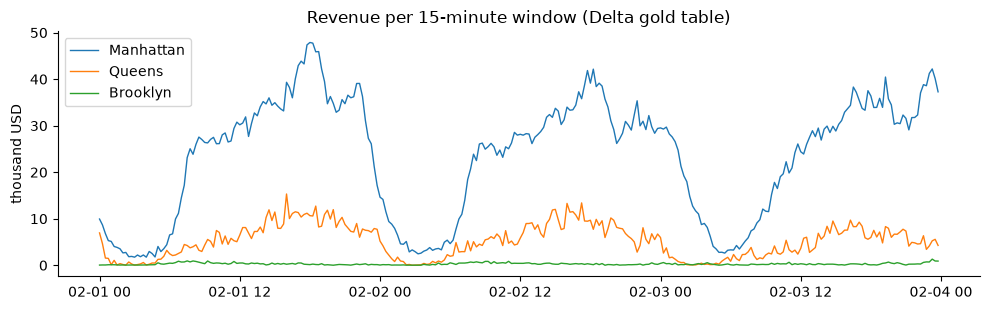

In [6]:
hist = DeltaTable.forPath(spark, str(GOLD)).history().select("version", "operation", "operationMetrics").toPandas()
hist["rows written"] = [int(m.get("numOutputRows", 0) or 0) for m in hist.operationMetrics]
print(hist[["version", "operation", "rows written"]].sort_values("version").to_string(index=False))
per_version = [(v, spark.read.format("delta").option("versionAsOf", v).load(str(GOLD)).agg(F.sum("trips")).first()[0])
               for v in sorted(hist.version)]
print("trips in the table per version:", per_version)

final = spark.read.format("delta").load(str(GOLD)).toPandas().sort_values("window_start")
fig, ax = plt.subplots(figsize=(10, 3.2))
for b in ["Manhattan", "Queens", "Brooklyn"]:
    s = final[final.Borough == b]
    ax.plot(s.window_start, s.revenue / 1000, label=b, lw=1)
ax.set(title="Revenue per 15-minute window (Delta gold table)", ylabel="thousand USD"); ax.legend()
plt.tight_layout(); plt.show()
spark.stop()

### 7. Explanation for the dashboard team

1. Every trip file is processed exactly once, because the checkpoint records the finished files and the MERGE makes
   a repeated micro-batch write the same values instead of new rows.
2. A restart (planned or after a crash) continues with the next unprocessed file; no manual bookkeeping is needed.
3. The watermark decides how late data may arrive: with 30 minutes, the two late files were dropped; with 72 hours
   they were counted, but Spark keeps three days of windows in state and windows stay "open" longer.
4. Every micro-batch is a Delta version, so a wrong number on the dashboard can be traced to the batch that wrote it.
5. In production, monitor input rows per batch, batch duration, the watermark delay and the number of dropped late
   rows (`numRowsDroppedByWatermark` in the query progress).

## Submission Checklist

- [ ] The stream uses an explicit schema, a watermark and a checkpoint.
- [ ] Re-running with the same checkpoint processes only new files (shown with counts).
- [ ] The Delta table equals the batch result, except for differences you explain.
- [ ] Delta history shows one version per micro-batch, and time travel works.

A solution is in `02-Streaming-Revenue-into-Delta-solution.ipynb`. Try the mission first.